# Practical 2, Part II: A Linear 1D Finite Element Code

**Materials Simulation Practical 2, implementation tasks** · Ali Ghelichkhani ([ali.ghelichkhani@fau.de](mailto:ali.ghelichkhani@fau.de)) · Supervisor: Yuxin Luo
Institute of Materials Simulation (WW8), FAU Erlangen-Nürnberg · Winter semester 2026/27

This notebook implements the finite element machinery derived in Part I (`report/main.pdf`) and
verifies every piece of it against the hand calculations given there. The structure follows the
eight steps listed at the end of the tutorial script:

| Task | Content | Section |
|------|---------|---------|
| 4.1 | linear shape functions, interpolation test | [1](#1) |
| 4.2 | shape function derivatives $B_i$ | [2](#2) |
| 5.1 | general quadrature routine | [3](#3) |
| 5.2 | closed Newton–Cotes rules and their exactness | [4](#4) |
| 5.3 | element stiffness, one-element bar, choice of solver | [5](#5) |
| 6.2, 6.3 | assembly routine, properties of the global matrix | [6](#6) |
| 7.2 | Dirichlet boundary conditions, non-zero values | [7](#7) |
| 8.1 | full 1D analysis, post-processing, varying boundary conditions | [8](#8) |

Throughout we use the unit system **N, mm**, so that stresses come out in N/mm² = MPa.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.linalg as sla

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True,
                     "grid.alpha": 0.3, "figure.autolayout": True})

# Material and geometry of Task 2.3 / 5.3 (units: N, mm)
E_MOD = 210_000.0   # Young's modulus [N/mm^2]
AREA  = 25.0        # cross-section   [mm^2]
LEN   = 50.0        # bar length      [mm]
FORCE = 5.0         # tip load        [N]

print(f"EA/l = {E_MOD * AREA / LEN:,.0f} N/mm")
print(f"analytical tip displacement u(l) = Fl/(EA) = {FORCE * LEN / (E_MOD * AREA):.6e} mm")
print(f"analytical stress            sigma = F/A  = {FORCE / AREA:.4f} N/mm^2")

EA/l = 105,000 N/mm
analytical tip displacement u(l) = Fl/(EA) = 4.761905e-05 mm
analytical stress            sigma = F/A  = 0.2000 N/mm^2


<a id="1"></a>
## 1 Shape functions (Task 4.1)

On a two-node element with nodes at $x_1^e$ and $x_2^e$, the linear Lagrange basis is

$$N_1(x) = \frac{x_2^e - x}{h}, \qquad N_2(x) = \frac{x - x_1^e}{h}, \qquad h = x_2^e - x_1^e,$$

with $N_i(x_j) = \delta_{ij}$ and $N_1 + N_2 = 1$. The routine takes the two node positions and an
evaluation point $\xi$ (scalar or array) and returns $\boldsymbol{N}(\xi) = [N_1, N_2]$, so that the
interpolation of eq. (5.5) of Part I is a plain matrix–vector product $\tilde u = \boldsymbol{N}\cdot\hat{\boldsymbol{u}}$.

In [2]:
def shape_functions(x1, x2, xi):
    """Row vector N(xi) = [N1, N2] of the linear Lagrange shape functions of element [x1, x2].

    Vectorised in xi: the last axis of the result always holds the two shape functions,
    so shape_functions(x1, x2, array_of_m_points) has shape (m, 2).
    """
    if x2 == x1:
        raise ValueError("element has zero length")
    xi = np.asarray(xi, dtype=float)
    return np.stack([(x2 - xi) / (x2 - x1), (xi - x1) / (x2 - x1)], axis=-1)


def interpolate(x1, x2, u_hat, xi):
    """Interpolated field value(s) u~(xi) = N(xi) . u_hat inside the element."""
    return shape_functions(x1, x2, xi) @ np.asarray(u_hat, dtype=float)


# Kronecker property and partition of unity
N = shape_functions(0.0, 2.0, np.array([0.0, 2.0]))
assert np.allclose(N, np.eye(2)), "N_i(x_j) = delta_ij violated"
assert np.allclose(shape_functions(0.0, 2.0, np.linspace(0, 2, 7)).sum(axis=1), 1.0)
print("N(x1) =", shape_functions(0.0, 2.0, 0.0), "   N(x2) =", shape_functions(0.0, 2.0, 2.0))
print("N(midpoint) =", shape_functions(0.0, 2.0, 1.0))

N(x1) = [1. 0.]    N(x2) = [0. 1.]
N(midpoint) = [0.5 0.5]


### Test with three functions

The shape functions span $\mathrm{span}\{N_1, N_2\} = \mathcal{P}_1$, so interpolation reproduces
exactly the affine functions and nothing else. We test
$f_1(x) = 3x + 2$ (affine), $f_2(x) = x^2$ (quadratic) and $f_3(x) = \sin(\pi x / 2)$ (transcendental)
on the element $[0, 2]$.

function                    max |error| on element
f1 = 3x + 2  (affine)                    4.441e-16
f2 = x^2     (quadratic)                 1.000e+00
f3 = sin(pi x / 2)                       1.000e+00


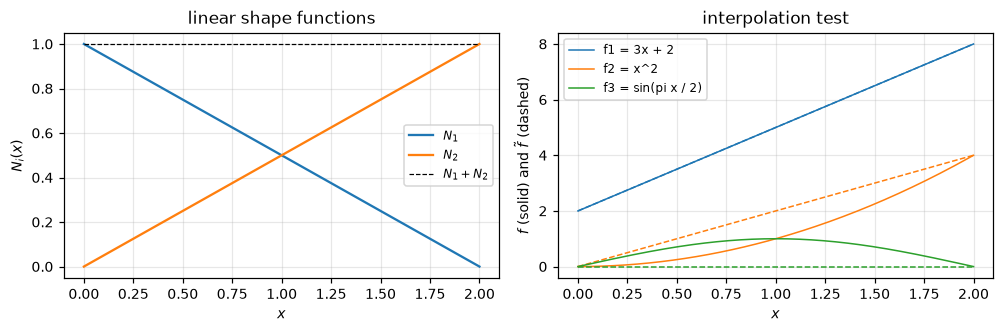

In [3]:
tests = {
    "f1 = 3x + 2  (affine)":        lambda x: 3.0 * x + 2.0,
    "f2 = x^2     (quadratic)":     lambda x: x ** 2,
    "f3 = sin(pi x / 2)":           lambda x: np.sin(np.pi * x / 2),
}
x1, x2 = 0.0, 2.0
xs = np.linspace(x1, x2, 201)

fig, ax = plt.subplots(1, 2, figsize=(9.2, 3.1))
ax[0].plot(xs, shape_functions(x1, x2, xs)[:, 0], label="$N_1$")
ax[0].plot(xs, shape_functions(x1, x2, xs)[:, 1], label="$N_2$")
ax[0].plot(xs, shape_functions(x1, x2, xs).sum(axis=1), "k--", lw=0.8, label="$N_1+N_2$")
ax[0].set(xlabel="$x$", ylabel="$N_i(x)$", title="linear shape functions")
ax[0].legend(fontsize=8)

print(f"{'function':<26}{'max |error| on element':>24}")
for name, f in tests.items():
    u_hat = np.array([f(x1), f(x2)])          # nodal values
    err = np.max(np.abs(interpolate(x1, x2, u_hat, xs) - f(xs)))
    print(f"{name:<26}{err:>24.3e}")
    ax[1].plot(xs, f(xs), lw=1.0, label=name.split("  ")[0])
    ax[1].plot(xs, interpolate(x1, x2, u_hat, xs), "--", lw=1.0, color=ax[1].lines[-1].get_color())
ax[1].set(xlabel="$x$", ylabel="$f$ (solid) and $\\tilde f$ (dashed)", title="interpolation test")
ax[1].legend(fontsize=8)
plt.show()

# only the affine function is reproduced exactly
assert np.max(np.abs(interpolate(x1, x2, [2.0, 8.0], xs) - (3 * xs + 2))) < 1e-13

**Result.** Only $f_1$ is reproduced to machine precision; the quadratic and the sine are
approximated by the secant through the nodal values, with the familiar $\mathcal{O}(h^2)$ error that
peaks at the element midpoint.

**Consequence for displacement and stress.** Inside a linear element the displacement is at best
affine, so the strain $\mathrm{d}\tilde u/\mathrm{d}x$ and therefore the stress $\sigma = E\,\mathrm{d}\tilde u/\mathrm{d}x$
are **constant** on the element and discontinuous across element boundaries. The stress field is one
order less accurate than the displacement field. For the bar of Task 2.3 (constant $EA$, $b = 0$) the
exact solution is itself affine, so it lies in the finite element space and is reproduced exactly at
any mesh size — which is what Sections 5 and 8 confirm numerically.

<a id="2"></a>
## 2 Shape function derivatives (Task 4.2)

Differentiating the shape functions gives the constant row vector

$$\boldsymbol{B}(x) = \left[\frac{\mathrm{d}N_1}{\mathrm{d}x},\ \frac{\mathrm{d}N_2}{\mathrm{d}x}\right]
= \left[-\frac1h,\ \frac1h\right], \qquad
\frac{\mathrm{d}\tilde u}{\mathrm{d}x} = \boldsymbol{B}\cdot\hat{\boldsymbol{u}} = \frac{\hat u_2 - \hat u_1}{h},$$

i.e. the difference quotient of the nodal values — the same expression as the first-order finite
difference of Practical 1.

function                    max |gradient error|
f1 = 3x + 2  (affine)                  0.000e+00
f2 = x^2     (quadratic)               2.000e+00
f3 = sin(pi x / 2)                     1.571e+00


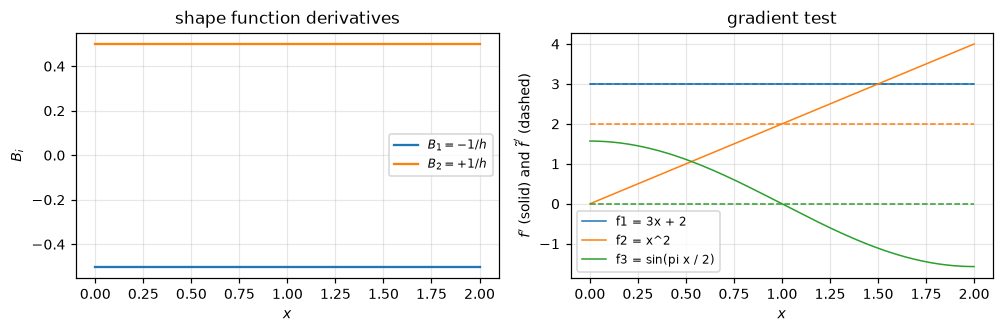

In [4]:
def shape_derivatives(x1, x2, xi):
    """Row vector B(xi) = [dN1/dx, dN2/dx] of the linear element [x1, x2] (constant in xi)."""
    if x2 == x1:
        raise ValueError("element has zero length")
    xi = np.asarray(xi, dtype=float)
    ones = np.ones_like(xi)
    return np.stack([-ones / (x2 - x1), ones / (x2 - x1)], axis=-1)


def interpolate_gradient(x1, x2, u_hat, xi):
    """Interpolated gradient du~/dx = B(xi) . u_hat inside the element."""
    return shape_derivatives(x1, x2, xi) @ np.asarray(u_hat, dtype=float)


fig, ax = plt.subplots(1, 2, figsize=(9.2, 3.1))
ax[0].plot(xs, shape_derivatives(x1, x2, xs)[:, 0], label="$B_1 = -1/h$")
ax[0].plot(xs, shape_derivatives(x1, x2, xs)[:, 1], label="$B_2 = +1/h$")
ax[0].set(xlabel="$x$", ylabel="$B_i$", title="shape function derivatives")
ax[0].legend(fontsize=8)

derivatives = {"f1 = 3x + 2  (affine)": lambda x: 3.0 + 0 * x,
               "f2 = x^2     (quadratic)": lambda x: 2.0 * x,
               "f3 = sin(pi x / 2)": lambda x: np.pi / 2 * np.cos(np.pi * x / 2)}

print(f"{'function':<26}{'max |gradient error|':>22}")
for (name, f), df in zip(tests.items(), derivatives.values()):
    u_hat = np.array([f(x1), f(x2)])
    grad = interpolate_gradient(x1, x2, u_hat, xs)
    print(f"{name:<26}{np.max(np.abs(grad - df(xs))):>22.3e}")
    ax[1].plot(xs, df(xs), lw=1.0, label=name.split("  ")[0])
    ax[1].plot(xs, grad, "--", lw=1.0, color=ax[1].lines[-1].get_color())
ax[1].set(xlabel="$x$", ylabel="$f'$ (solid) and $\\tilde f'$ (dashed)", title="gradient test")
ax[1].legend(fontsize=8)
plt.show()

assert np.allclose(interpolate_gradient(x1, x2, [2.0, 8.0], xs), 3.0)

The gradient of the affine function is recovered exactly; for the other two the piecewise constant
approximation equals the exact derivative only at the single point where the secant is parallel to
the tangent (the mean value theorem), and the error is $\mathcal{O}(h)$ everywhere else. This is the
numerical demonstration of the statement in Part I that the stress converges one order more slowly
than the displacement.

<a id="3"></a>
## 3 Numerical integration (Task 5.1)

$$\int_{x_1}^{x_2} f(x)\,\mathrm{d}x \;\approx\; (x_2 - x_1)\sum_{j=1}^{n}\lambda_j\,f(\zeta_j)$$

The quadrature points are given as **relative** positions $\zeta_j \in [0,1]$ and mapped to the
element by $x_j = x_1 + \zeta_j (x_2 - x_1)$; the same table then serves every element. The integrand
is passed as a callable, so the identical routine integrates a scalar body force and the $2\times2$
matrix integrand $\boldsymbol{B}^{\mathsf T}EA\boldsymbol{B}$ without modification.

As required by the task, the first version implements only $n = 2$ and raises an exception otherwise.

In [5]:
def quadrature_trapezoidal(f, x1, x2, n, lam=None, zeta=None):
    """First version of Task 5.1: trapezoidal rule only, exception for n != 2."""
    if n != 2:
        raise NotImplementedError(f"only n = 2 (trapezoidal rule) is implemented, got n = {n}")
    if lam is None or zeta is None:
        lam, zeta = np.array([0.5, 0.5]), np.array([0.0, 1.0])
    pts = x1 + np.asarray(zeta) * (x2 - x1)
    return (x2 - x1) * sum(l * np.asarray(f(p)) for l, p in zip(lam, pts))


print("int_0^1 x dx  =", quadrature_trapezoidal(lambda x: x, 0.0, 1.0, 2), " (exact 0.5)")
try:
    quadrature_trapezoidal(lambda x: x, 0.0, 1.0, 3)
except NotImplementedError as exc:
    print("n = 3 ->", exc)

int_0^1 x dx  = 0.5  (exact 0.5)
n = 3 -> only n = 2 (trapezoidal rule) is implemented, got n = 3


<a id="4"></a>
## 4 Closed Newton–Cotes schemes (Task 5.2)

Closed Newton–Cotes rules place $n$ equidistant points on $[x_1, x_2]$, both ends included, and
choose the weights so that the interpolating polynomial of degree $n-1$ through those points is
integrated exactly.

| $n$ | name | weights $\lambda$ | points $\zeta$ |
|-----|------|-------------------|----------------|
| 2 | trapezoidal rule | $\tfrac12,\tfrac12$ | $0, 1$ |
| 3 | Simpson rule | $\tfrac16,\tfrac46,\tfrac16$ | $0, \tfrac12, 1$ |
| 4 | 3/8 rule | $\tfrac18,\tfrac38,\tfrac38,\tfrac18$ | $0, \tfrac13, \tfrac23, 1$ |

In [6]:
NEWTON_COTES = {
    2: (np.array([1 / 2, 1 / 2]),                       np.array([0.0, 1.0])),
    3: (np.array([1 / 6, 4 / 6, 1 / 6]),                np.array([0.0, 1 / 2, 1.0])),
    4: (np.array([1 / 8, 3 / 8, 3 / 8, 1 / 8]),         np.array([0.0, 1 / 3, 2 / 3, 1.0])),
}


def newton_cotes(n):
    """Weights and relative points of the closed Newton-Cotes rule with n points."""
    if n not in NEWTON_COTES:
        raise NotImplementedError(
            f"closed Newton-Cotes with n = {n} points is not tabulated (available: "
            f"{sorted(NEWTON_COTES)})")
    return NEWTON_COTES[n]


def quadrature(f, x1, x2, n, lam=None, zeta=None):
    """General version of Task 5.1/5.2.

    f     : callable, may return a scalar or an array (the element matrix integrand)
    x1,x2 : integration bounds
    n     : number of integration points
    lam   : n weights; taken from the Newton-Cotes table if omitted
    zeta  : n relative points in [0, 1]; taken from the table if omitted
    """
    if lam is None or zeta is None:
        lam, zeta = newton_cotes(n)
    lam, zeta = np.asarray(lam, float), np.asarray(zeta, float)
    if lam.size != n or zeta.size != n:
        raise ValueError(f"lambda and zeta must both have n = {n} entries")
    if not np.isclose(lam.sum(), 1.0):
        raise ValueError("weights must sum to one (constants integrated exactly)")
    pts = x1 + zeta * (x2 - x1)
    return (x2 - x1) * sum(l * np.asarray(f(p)) for l, p in zip(lam, pts))


assert np.isclose(quadrature(lambda x: x ** 3, 0.0, 1.0, 3), 0.25)   # Simpson is exact for cubics
print("Simpson, int_0^1 x^3 dx =", quadrature(lambda x: x ** 3, 0.0, 1.0, 3))

Simpson, int_0^1 x^3 dx = 0.25


### Exactness test

We integrate monomials $x^p$ over $[0, 1]$ and compare with $1/(p+1)$. The expectation from Part I is
that the $n$-point rule is exact up to degree $n-1$ and, for **odd** $n$, up to degree $n$ (symmetry
argument).

In [7]:
degrees = range(7)
rows = []
for n in (2, 3, 4):
    errs = [abs(quadrature(lambda x, p=p: x ** p, 0.0, 1.0, n) - 1 / (p + 1)) for p in degrees]
    exact_to = max([p for p, e in zip(degrees, errs) if e < 1e-13])
    rows.append((n, errs, exact_to))

print(f"{'n':>2}  " + "  ".join(f"deg {p}" for p in degrees) + "   exact up to")
for n, errs, exact_to in rows:
    print(f"{n:>2}  " + "  ".join(("  ok  " if e < 1e-13 else f"{e:5.0e}") for e in errs)
          + f"   degree {exact_to}")

assert [r[2] for r in rows] == [1, 3, 3], "Newton-Cotes exactness does not match the theory"

 n  deg 0  deg 1  deg 2  deg 3  deg 4  deg 5  deg 6   exact up to
 2    ok      ok    2e-01  2e-01  3e-01  3e-01  4e-01   degree 1
 3    ok      ok      ok      ok    8e-03  2e-02  3e-02   degree 3
 4    ok      ok      ok      ok    4e-03  9e-03  2e-02   degree 3


The table confirms the theory: the trapezoidal rule is exact to degree 1, Simpson and the 3/8 rule
both to degree 3. Simpson gains one degree over its construction order because it has an odd number
of symmetric points; the 3/8 rule (even $n$) does not, which is why it is exact to the same degree as
Simpson while using one more point.

**Points needed for the element integrals.** With linear shape functions and constant $EA$ the
stiffness integrand $\boldsymbol B^{\mathsf T} EA \boldsymbol B$ is constant ($\mathcal{P}_0$) and the
load integrand $\boldsymbol N^{\mathsf T} A\rho b$ is at most linear ($\mathcal{P}_1$), so $n = 2$
integrates both exactly and more points buy nothing. For quadratic shape functions $\boldsymbol B$ is
linear, $\boldsymbol B^{\mathsf T}\boldsymbol B$ is quadratic, and $n = 3$ (Simpson) is required.

<a id="5"></a>
## 5 The element level (Task 5.3)

$$\boldsymbol K^e = \int_e \boldsymbol B^{\mathsf T}(x)\,E(x)A(x)\,\boldsymbol B(x)\,\mathrm{d}x,
\qquad
\boldsymbol f^e_{\mathcal B} = \int_e \boldsymbol N^{\mathsf T}(x)\,A(x)\rho\,b(x)\,\mathrm{d}x.$$

Both are evaluated with the quadrature routine of Section 3. $E$ and $A$ are passed as callables so
that a bar with a varying cross-section needs no extra code.

In [8]:
def element_stiffness(x1, x2, E, A, n_quad=2):
    """Element stiffness matrix K^e = int B^T E A B dx of a linear two-node element."""
    def integrand(x):
        B = shape_derivatives(x1, x2, x)
        return np.outer(B, B) * E(x) * A(x)
    return quadrature(integrand, x1, x2, n_quad)


def element_load(x1, x2, rho, A, b, n_quad=2):
    """Element body-force vector f^e_B = int N^T A rho b dx."""
    def integrand(x):
        return shape_functions(x1, x2, x) * A(x) * rho * b(x)
    return quadrature(integrand, x1, x2, n_quad)


Ke = element_stiffness(0.0, LEN, lambda x: E_MOD, lambda x: AREA)
print("K^e =\n", Ke)
print("\nEA/l =", E_MOD * AREA / LEN)
assert np.allclose(Ke, E_MOD * AREA / LEN * np.array([[1, -1], [-1, 1]]))
print("symmetric:", np.allclose(Ke, Ke.T),
      "| row sums:", Ke.sum(axis=1),
      "| rank:", np.linalg.matrix_rank(Ke), "of 2 -> singular",
      "| K^e . [1,1]^T:", Ke @ np.ones(2))

K^e =
 [[ 105000. -105000.]
 [-105000.  105000.]]

EA/l = 105000.0
symmetric: True | row sums: [0. 0.] | rank: 1 of 2 -> singular | K^e . [1,1]^T: [0. 0.]


The element matrix is exactly $\frac{EA}{h}\begin{bmatrix}1&-1\\-1&1\end{bmatrix}$ of eq. (7.1) of
Part I: symmetric, zero row sums, singular with the null vector $[1,1]^{\mathsf T}$ — a rigid-body
translation of both nodes produces no force.

### The one-element bar solved by hand and by the code

With $u_1 = 0$ the first row (which contains the unknown reaction $R_1$) is deleted and the system
collapses to the scalar equation

$$105\,000\ \frac{\mathrm N}{\mathrm{mm}}\ \hat u_2 = 5\ \mathrm{N}
\qquad\Longrightarrow\qquad \hat u_2 = 4.7619\cdot10^{-5}\ \mathrm{mm},$$

which must coincide with the analytical $u(l) = Fl/(EA)$.

In [9]:
# hand calculation of Part I, eq. (7.5)
Kr_hand = np.array([[E_MOD * AREA / LEN]])
fr_hand = np.array([FORCE])
u2_hand = np.linalg.solve(Kr_hand, fr_hand)[0]

u2_exact = FORCE * LEN / (E_MOD * AREA)
print(f"hand / code  u2 = {u2_hand:.12e} mm")
print(f"analytical   u2 = {u2_exact:.12e} mm")
print(f"relative error  = {abs(u2_hand - u2_exact) / u2_exact:.3e}")

sigma = E_MOD * shape_derivatives(0.0, LEN, 0.0) @ np.array([0.0, u2_hand])
print(f"\nstress sigma = E B . u = {sigma:.6f} N/mm^2  (analytical F/A = {FORCE / AREA:.6f})")
print(f"reaction R1  = {-E_MOD * AREA / LEN * u2_hand:.6f} N  (equilibrium: -F = {-FORCE} N)")

assert np.isclose(u2_hand, u2_exact, rtol=1e-14)
assert np.isclose(sigma, FORCE / AREA)

hand / code  u2 = 4.761904761905e-05 mm
analytical   u2 = 4.761904761905e-05 mm
relative error  = 1.423e-16

stress sigma = E B . u = 0.200000 N/mm^2  (analytical F/A = 0.200000)
reaction R1  = -5.000000 N  (equilibrium: -F = -5.0 N)


**Agreement is exact, not approximate.** The analytical solution $u(x) = Fx/(EA)$ is affine and
therefore lies in the finite element space of linear elements; the Galerkin solution is the best
approximation from that space in the energy norm, so it *is* the exact solution. Mesh refinement
cannot improve it (Section 8 confirms this).

### Choice of solver

After the Dirichlet reduction the stiffness matrix is **symmetric, positive definite, tridiagonal**
and very sparse. That dictates the solver:

* A **direct Cholesky factorisation** $K_r = LL^{\mathsf T}$ exists precisely because $K_r$ is
  symmetric positive definite, needs half the operations and storage of an LU factorisation and
  requires no pivoting, since an SPD matrix factorises stably without row interchanges. Exploiting
  the band structure makes the cost linear in the number of unknowns, $\mathcal O(n b^2)$ with
  half-bandwidth $b = 1$, instead of the $\mathcal O(n^3)$ of a dense solve.
* Gaussian elimination without pivoting (the Thomas algorithm for tridiagonal systems) is the same
  thing written out by hand — this is what the hand calculation above does.
* Iterative solvers (preconditioned conjugate gradients) only pay off in 2D/3D, where the bandwidth
  grows with the mesh and direct fill-in becomes prohibitive.

Below, the small systems use the dense LAPACK solve `numpy.linalg.solve`, and the banded Cholesky
solver `scipy.linalg.solveh_banded` is used for the convergence study. The next cell checks that the
two give the same answer.

In [10]:
def solve_spd_banded(K, f):
    """Cholesky solve of a symmetric positive definite tridiagonal system in banded storage."""
    ab = np.zeros((2, K.shape[0]))
    ab[0, 1:] = np.diag(K, 1)     # upper off-diagonal
    ab[1, :] = np.diag(K)         # main diagonal
    return sla.solveh_banded(ab, f)


Kt = (E_MOD * AREA / (LEN / 4)) * (np.diag([2.0, 2.0, 2.0, 1.0])
                                   + np.diag([-1.0, -1.0, -1.0], 1)
                                   + np.diag([-1.0, -1.0, -1.0], -1))
ft = np.array([0.0, 0.0, 0.0, FORCE])
print("dense LAPACK :", np.linalg.solve(Kt, ft))
print("banded Chol. :", solve_spd_banded(Kt, ft))
print("Cholesky exists (SPD):", np.all(np.linalg.eigvalsh(Kt) > 0))
assert np.allclose(np.linalg.solve(Kt, ft), solve_spd_banded(Kt, ft))

dense LAPACK : [1.19047619e-05 2.38095238e-05 3.57142857e-05 4.76190476e-05]
banded Chol. : [1.19047619e-05 2.38095238e-05 3.57142857e-05 4.76190476e-05]
Cholesky exists (SPD): True


<a id="6"></a>
## 6 Assembly (Tasks 6.2 and 6.3)

With a connectivity map $k \mapsto (n_1^k, n_2^k)$ from local to global node numbers,

$$K_{n_a^k\, n_b^k} \mathrel{+}= K^{e_k}_{ab}.$$

The accumulation is essential: in 1D every interior node is shared by two elements and its diagonal
entry receives $EA/h$ from each of them.

In [11]:
def assemble(K_global, K_element, nodes):
    """Add an element matrix block-wise into the global matrix at the given global node numbers."""
    nodes = np.asarray(nodes, dtype=int)
    if K_element.shape != (nodes.size, nodes.size):
        raise ValueError("element matrix and node list have inconsistent sizes")
    K_global[np.ix_(nodes, nodes)] += K_element
    return K_global


def assemble_vector(f_global, f_element, nodes):
    """Same for an element right-hand side vector."""
    f_global[np.asarray(nodes, dtype=int)] += f_element
    return f_global

### Task 6.3 — the assembled matrix for the spring chain

For three unit springs ($c = 1$, i.e. $K^e = [[1,-1],[-1,1]]$) the assembled matrix must equal eq.
(8.3) of Part I.

In [12]:
K_spring_e = np.array([[1.0, -1.0], [-1.0, 1.0]])     # c = 1
K_spring = np.zeros((4, 4))
for e in range(3):
    assemble(K_spring, K_spring_e, [e, e + 1])

print("assembled global stiffness matrix (c = 1):\n", K_spring)

K_script = np.array([[1, -1, 0, 0],
                     [-1, 2, -1, 0],
                     [0, -1, 2, -1],
                     [0, 0, -1, 1]], dtype=float)
assert np.allclose(K_spring, K_script), "assembly does not reproduce eq. (8.3) of the report"
print("\nidentical to the hand-derived system of Task 6.1:", np.allclose(K_spring, K_script))

assembled global stiffness matrix (c = 1):
 [[ 1. -1.  0.  0.]
 [-1.  2. -1.  0.]
 [ 0. -1.  2. -1.]
 [ 0.  0. -1.  1.]]

identical to the hand-derived system of Task 6.1: True


In [13]:
# Properties of the global stiffness matrix (Task 6.3)
eigvals = np.linalg.eigvalsh(K_spring)
rank = np.linalg.matrix_rank(K_spring)
null = np.ones(4)

print(f"symmetric                : {np.allclose(K_spring, K_spring.T)}")
print(f"row sums                 : {K_spring.sum(axis=1)}")
print(f"eigenvalues              : {np.round(eigvals, 6)}")
print(f"positive semi-definite   : {np.all(eigvals > -1e-12)}")
print(f"rank / size              : {rank} / {K_spring.shape[0]}  -> singular")
print(f"K . [1,1,1,1]^T          : {K_spring @ null}  -> rigid-body translation is the null space")
print(f"bandwidth (non-zeros/row): {np.max(np.count_nonzero(K_spring, axis=1))}  -> tridiagonal")

assert rank == 3 and np.allclose(K_spring @ null, 0.0)

f_spring = np.array([0.0, 0.0, 0.0, FORCE])
print(f"\nsolvability condition  1^T f = {null @ f_spring}  != 0  -> no static solution yet")

symmetric                : True
row sums                 : [0. 0. 0. 0.]
eigenvalues              : [0.       0.585786 2.       3.414214]
positive semi-definite   : True
rank / size              : 3 / 4  -> singular
K . [1,1,1,1]^T          : [0. 0. 0. 0.]  -> rigid-body translation is the null space
bandwidth (non-zeros/row): 3  -> tridiagonal

solvability condition  1^T f = 5.0  != 0  -> no static solution yet


**Why the system cannot be solved yet.** The assembled matrix is singular with
$\mathrm{rank}\,K = n-1$ and the null space spanned by $\mathbf 1 = [1,1,1,1]^{\mathsf T}$. Physically,
the chain still floats freely: nothing tells it where it is, so any solution can be shifted by an
arbitrary rigid-body translation $\alpha\mathbf 1$ without changing a single spring length and hence
without changing any force. Read along the rows, the same statement says that a solution exists only
if the load is orthogonal to the null space, $\mathbf 1^{\mathsf T}\boldsymbol f = \sum_i f_i = 0$ —
the applied forces must be in equilibrium among themselves, otherwise the structure accelerates and
the *static* problem has no solution at all. Here $\sum_i f_i = F \neq 0$, consistent with the fact
that the reaction force $R_1$ is still missing. Imposing $u_1 = 0$ supplies that reaction, removes
the rigid-body mode, and makes the reduced matrix positive definite.

<a id="7"></a>
## 7 Dirichlet boundary conditions (Tasks 7.1 and 7.2)

Split $\boldsymbol d = \boldsymbol d_\Gamma + \check{\boldsymbol d}$ into the prescribed and the
unknown part, move the induced forces to the right-hand side and reduce with the rectangular
permutation (selection) matrix $\boldsymbol P \in \mathbb{R}^{(n-m)\times n}$:

$$\underbrace{(\boldsymbol P\boldsymbol K\boldsymbol P^{\mathsf T})}_{\boldsymbol K_r}\boldsymbol d_r
= \underbrace{\boldsymbol P(\boldsymbol f - \boldsymbol K\boldsymbol d_\Gamma)}_{\boldsymbol f_r},
\qquad \boldsymbol d = \boldsymbol P^{\mathsf T}\boldsymbol d_r + \boldsymbol d_\Gamma.$$

The term $\boldsymbol K\boldsymbol d_\Gamma$ is the one that is easy to forget — dropping it is
correct only for homogeneous conditions.

In [14]:
def permutation_matrix(n, fixed):
    """Rectangular selection matrix P of shape (n - m, n) that keeps the unconstrained nodes."""
    fixed = set(int(i) for i in fixed)
    free = [i for i in range(n) if i not in fixed]
    P = np.zeros((len(free), n))
    P[np.arange(len(free)), free] = 1.0
    return P


def apply_dirichlet(K, f, fixed, values):
    """Reduce K d = f for prescribed displacements, including non-zero ones.

    Returns the reduced system, the permutation matrix and the vector of prescribed values.
    """
    fixed = np.atleast_1d(np.asarray(fixed, dtype=int))
    values = np.atleast_1d(np.asarray(values, dtype=float))
    if fixed.size != values.size:
        raise ValueError("one prescribed value per constrained node is required")
    d_gamma = np.zeros(K.shape[0])
    d_gamma[fixed] = values                 # <- the non-zero part
    P = permutation_matrix(K.shape[0], fixed)
    return P @ K @ P.T, P @ (f - K @ d_gamma), P, d_gamma


# Task 7.1: the permutation matrix for a 4x4 system constrained at the first node
P = permutation_matrix(4, [0])
print("P =\n", P, "\nshape:", P.shape, " (n - m) x n = 3 x 4")
assert np.allclose(P @ P.T, np.eye(3))              # P_ik P_jk = delta_ij
print("\nP P^T = I_3 :", np.allclose(P @ P.T, np.eye(3)))
print("P^T P != I_4 (P is not invertible):", not np.allclose(P.T @ P, np.eye(4)))

P =
 [[0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]] 
shape: (3, 4)  (n - m) x n = 3 x 4

P P^T = I_3 : True
P^T P != I_4 (P is not invertible): True


In [15]:
# Test case 1: spring chain with u1 = 0 and the force F at node 4
Kr, fr, P, dG = apply_dirichlet(K_spring, f_spring, fixed=[0], values=[0.0])
print("reduced K_r =\n", Kr)
print("reduced f_r =", fr)
d = P.T @ np.linalg.solve(Kr, fr) + dG
print("\nd =", d, "  (expected F/c * [0, 1, 2, 3] =", FORCE * np.array([0, 1, 2, 3]), ")")
R = K_spring @ d - f_spring
print("reactions R =", R, " -> R1 = -F =", -FORCE)

assert np.allclose(d, FORCE * np.array([0.0, 1.0, 2.0, 3.0]))
assert np.isclose(R[0], -FORCE) and np.allclose(R[1:], 0.0)
assert np.allclose(Kr, np.array([[2., -1., 0.], [-1., 2., -1.], [0., -1., 1.]]))
print("\nK_r matches eq. (9.5) of the report, and it is now positive definite:",
      np.all(np.linalg.eigvalsh(Kr) > 0))

reduced K_r =
 [[ 2. -1.  0.]
 [-1.  2. -1.]
 [ 0. -1.  1.]]
reduced f_r = [0. 0. 5.]

d = [ 0.  5. 10. 15.]   (expected F/c * [0, 1, 2, 3] = [ 0.  5. 10. 15.] )
reactions R = [-5.  0.  0.  0.]  -> R1 = -F = -5.0

K_r matches eq. (9.5) of the report, and it is now positive definite: True


In [16]:
# Test case 2: the Neumann condition replaced by a second, NON-ZERO Dirichlet condition
u_bar = 0.3
Kr2, fr2, P2, dG2 = apply_dirichlet(K_spring, np.zeros(4), fixed=[0, 3], values=[0.0, u_bar])
print("reduced K_r =\n", Kr2)
print("reduced f_r =", fr2, "  <- non-zero only because of K . d_Gamma")
d2 = P2.T @ np.linalg.solve(Kr2, fr2) + dG2
print("\nd =", d2, "  (expected uniform stretch u_bar/3 * [0, 1, 2, 3] =",
      u_bar / 3 * np.array([0, 1, 2, 3]), ")")
R2 = K_spring @ d2
print("reactions R =", R2, "  sum =", R2.sum(), "-> global equilibrium")

assert np.allclose(d2, u_bar / 3 * np.array([0.0, 1.0, 2.0, 3.0]))
assert np.isclose(R2.sum(), 0.0, atol=1e-12)

# naive reduction that forgets K . d_Gamma gives the wrong answer
d_wrong = np.zeros(4); d_wrong[[0, 3]] = [0.0, u_bar]
d_wrong[[1, 2]] = np.linalg.solve(K_spring[np.ix_([1, 2], [1, 2])], np.zeros(2))
print("\nforgetting K.d_Gamma gives d =", d_wrong, " <- wrong")

reduced K_r =
 [[ 2. -1.]
 [-1.  2.]]
reduced f_r = [0.  0.3]   <- non-zero only because of K . d_Gamma

d = [0.  0.1 0.2 0.3]   (expected uniform stretch u_bar/3 * [0, 1, 2, 3] = [0.  0.1 0.2 0.3] )
reactions R = [-0.1  0.   0.   0.1]   sum = 1.3877787807814457e-17 -> global equilibrium

forgetting K.d_Gamma gives d = [0.  0.  0.  0.3]  <- wrong


<a id="8"></a>
## 8 Full finite element analysis (Task 8.1)

The driver below performs all eight steps of the script: mesh, element matrices, assembly, external
loads, Dirichlet reduction, solve, reconstruction, and post-processing of the stress as
$\tilde\sigma = E\,\boldsymbol B\cdot\hat{\boldsymbol u}$ on each element.

In [17]:
def _as_callable(value):
    return value if callable(value) else (lambda x, v=float(value): v)


def fe_analysis(length, n_el, E, A, forces=None, rho=0.0, b=0.0,
                fixed=(0,), values=(0.0,), n_quad=2):
    """Linear 1D finite element analysis of a bar.

    length  : bar length
    n_el    : number of equally sized two-node elements
    E, A    : Young's modulus and cross-section, scalar or callable of x
    forces  : {global node index: nodal force} for the Neumann conditions
    rho, b  : density and body-force density (per unit mass), b scalar or callable
    fixed   : global node indices with prescribed displacement
    values  : the prescribed displacements, same length as `fixed`
    n_quad  : number of Newton-Cotes integration points per element
    """
    E_f, A_f, b_f = _as_callable(E), _as_callable(A), _as_callable(b)
    x = np.linspace(0.0, length, n_el + 1)
    n_nodes = n_el + 1

    # 5. assembly of the element contributions
    K = np.zeros((n_nodes, n_nodes))
    f = np.zeros(n_nodes)
    for e in range(n_el):
        nodes = [e, e + 1]
        assemble(K, element_stiffness(x[e], x[e + 1], E_f, A_f, n_quad), nodes)
        if rho != 0.0:
            assemble_vector(f, element_load(x[e], x[e + 1], rho, A_f, b_f, n_quad), nodes)

    # Neumann conditions: simply insert the external forces at the right positions
    for node, value in (forces or {}).items():
        f[node] += value

    # 6./7. boundary conditions and solve
    Kr, fr, P, d_gamma = apply_dirichlet(K, f, fixed, values)
    d = P.T @ np.linalg.solve(Kr, fr) + d_gamma

    # 8. post-processing
    reactions = K @ d - f
    strain = np.array([shape_derivatives(x[e], x[e + 1], 0.0) @ d[[e, e + 1]] for e in range(n_el)])
    stress = np.array([E_f(0.5 * (x[e] + x[e + 1])) * strain[e] for e in range(n_el)])
    return dict(x=x, d=d, K=K, f=f, reactions=reactions, strain=strain, stress=stress)


def plot_result(res, title, exact_u=None, exact_sig=None):
    """Displacement (nodal, piecewise linear) and stress (piecewise constant) of one analysis."""
    x, d, sig = res["x"], res["d"], res["stress"]
    fig, ax = plt.subplots(1, 2, figsize=(9.2, 3.0))
    ax[0].plot(x, d, "o-", ms=4, lw=1.2, label="FE")
    if exact_u is not None:
        xf = np.linspace(x[0], x[-1], 300)
        ax[0].plot(xf, exact_u(xf), "k--", lw=0.9, label="analytical")
    ax[0].set(xlabel="$x$ [mm]", ylabel="$u$ [mm]", title=f"{title} — displacement")
    ax[0].legend(fontsize=8)
    ax[1].stairs(sig, x, baseline=None, lw=1.4, label="FE (element-wise)")
    if exact_sig is not None:
        xf = np.linspace(x[0], x[-1], 300)
        ax[1].plot(xf, exact_sig(xf), "k--", lw=0.9, label="analytical")
    ax[1].set(xlabel="$x$ [mm]", ylabel=r"$\sigma$ [N/mm$^2$]", title=f"{title} — stress")
    ax[1].legend(fontsize=8)
    plt.show()

### Case A — the problem of Task 2.3 with six elements

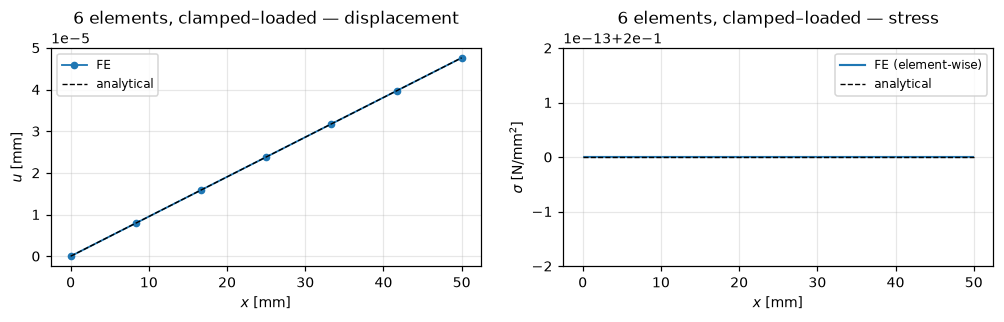

nodal displacements [mm]: [0.00000000e+00 7.93650794e-06 1.58730159e-05 2.38095238e-05
 3.17460317e-05 3.96825397e-05 4.76190476e-05]
element stresses [N/mm^2]: [0.2 0.2 0.2 0.2 0.2 0.2]
reaction at the clamp    : -5.000000 N  (= -F)
max |u - u_exact| / u(l) : 5.692e-16


In [18]:
res6 = fe_analysis(LEN, 6, E_MOD, AREA, forces={6: FORCE})
plot_result(res6, "6 elements, clamped–loaded",
            exact_u=lambda x: FORCE * x / (E_MOD * AREA),
            exact_sig=lambda x: np.full_like(x, FORCE / AREA))

print("nodal displacements [mm]:", np.array2string(res6["d"], precision=8))
print("element stresses [N/mm^2]:", np.array2string(res6["stress"], precision=8))
print("reaction at the clamp    :", f"{res6['reactions'][0]:.6f} N  (= -F)")
print("max |u - u_exact| / u(l) :",
      f"{np.max(np.abs(res6['d'] - FORCE * res6['x'] / (E_MOD * AREA))) / (FORCE * LEN / (E_MOD * AREA)):.3e}")

assert np.allclose(res6["d"], FORCE * res6["x"] / (E_MOD * AREA))
assert np.allclose(res6["stress"], FORCE / AREA)
assert np.isclose(res6["reactions"][0], -FORCE)

The six-element solution is exact to machine precision, for the reason established in Section 5: the
analytical displacement is affine and lies in the finite element space. Refining the mesh for *this*
problem changes nothing — the run verifies the code rather than improving the answer.

### Case B — two forces (a second Neumann condition in the interior)

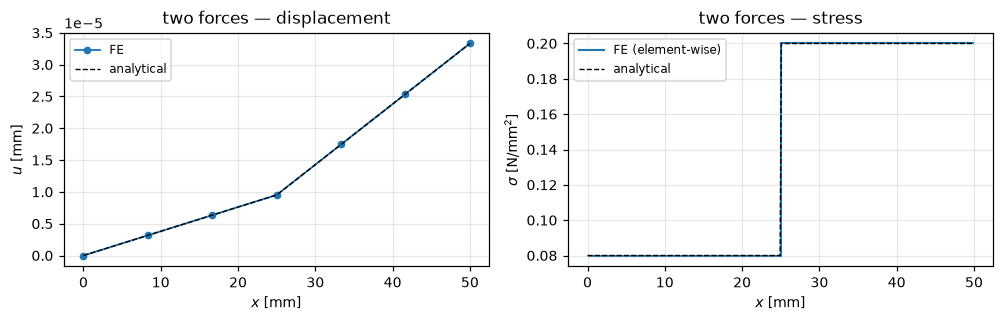

element stresses [N/mm^2]: [0.08 0.08 0.08 0.2  0.2  0.2 ]
expected                 : 0.08 then 0.2
reaction at the clamp    : -2.000000 N  (= -(F + F_mid) = -2.0)


In [19]:
F_mid = -3.0   # compressive load at node 3 (x = 25 mm)
resB = fe_analysis(LEN, 6, E_MOD, AREA, forces={3: F_mid, 6: FORCE})


def uB(x):
    # N(x) = F for x > l/2, and F + F_mid for x < l/2
    N = np.where(x < LEN / 2, FORCE + F_mid, FORCE)
    return np.where(x < LEN / 2,
                    N * x / (E_MOD * AREA),
                    (FORCE + F_mid) * (LEN / 2) / (E_MOD * AREA) + FORCE * (x - LEN / 2) / (E_MOD * AREA))


plot_result(resB, "two forces", exact_u=uB,
            exact_sig=lambda x: np.where(x < LEN / 2, (FORCE + F_mid) / AREA, FORCE / AREA))
print("element stresses [N/mm^2]:", np.array2string(resB["stress"], precision=6))
print("expected                 :", (FORCE + F_mid) / AREA, "then", FORCE / AREA)
print("reaction at the clamp    :", f"{resB['reactions'][0]:.6f} N  (= -(F + F_mid) = {-(FORCE + F_mid)})")

assert np.allclose(resB["stress"][:3], (FORCE + F_mid) / AREA)
assert np.allclose(resB["stress"][3:], FORCE / AREA)

The stress is piecewise constant with a jump at the loaded node, exactly as the analytical normal
force distribution demands. Linear elements capture this without error because the exact displacement
is piecewise affine and the mesh has a node at the discontinuity.

### Case C — the Neumann condition replaced by a prescribed displacement

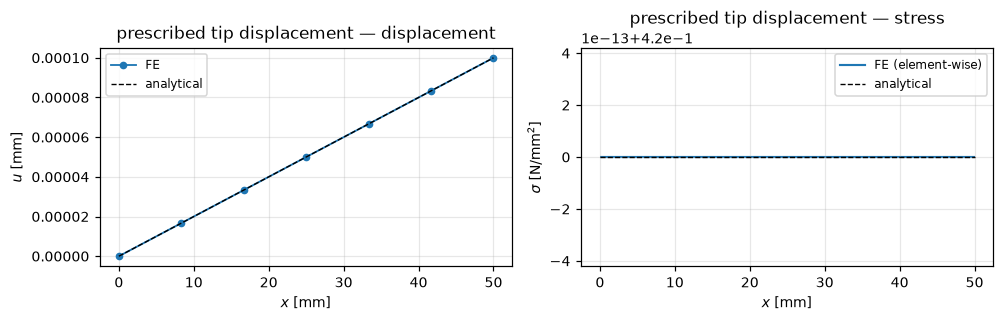

stress  : 0.42000000 N/mm^2   (E u_tip / l = 0.42000000)
reactions: [-1.05000000e+01  0.00000000e+00  0.00000000e+00  0.00000000e+00
  1.42108547e-14 -1.42108547e-14  1.05000000e+01]  sum = -1.60e-14


In [20]:
u_tip = 1.0e-4   # mm
resC = fe_analysis(LEN, 6, E_MOD, AREA, fixed=[0, 6], values=[0.0, u_tip])
plot_result(resC, "prescribed tip displacement",
            exact_u=lambda x: u_tip * x / LEN,
            exact_sig=lambda x: np.full_like(x, E_MOD * u_tip / LEN))

print("stress  :", f"{resC['stress'][0]:.8f} N/mm^2   (E u_tip / l = {E_MOD * u_tip / LEN:.8f})")
print("reactions:", np.array2string(resC["reactions"], precision=8),
      " sum =", f"{resC['reactions'].sum():.2e}")

assert np.allclose(resC["stress"], E_MOD * u_tip / LEN)
assert np.isclose(resC["reactions"].sum(), 0.0, atol=1e-10)
assert np.isclose(resC["reactions"][6], E_MOD * AREA * u_tip / LEN)

The two reactions are equal and opposite, $\mp EA\bar u/l$, so global equilibrium holds — a useful
check that the non-zero Dirichlet implementation of Section 7 is correct.

### Case D — a problem that is *not* in the finite element space: tapered bar

Giving the bar a linearly varying cross-section $A(x) = A_0\,(1 - \alpha x/l)$ makes the exact
displacement logarithmic,

$$u(x) = \frac{F\,l}{E A_0 \alpha}\,\ln\!\left(\frac{1}{1 - \alpha x/l}\right),$$

which no longer lies in the space of piecewise linear functions. Now a genuine discretisation error
appears and we can measure the convergence rates.

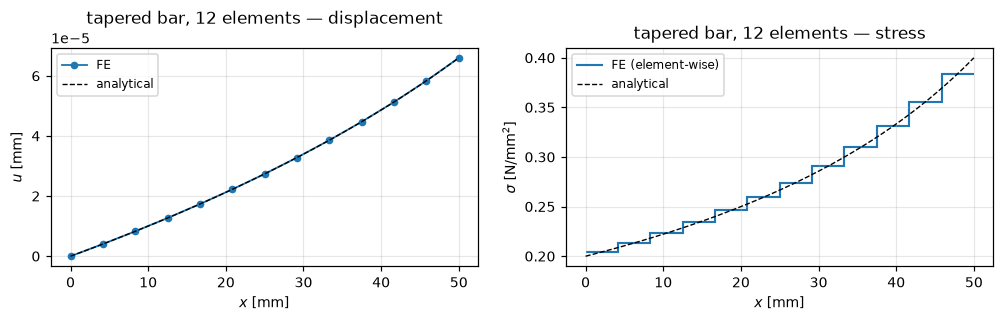

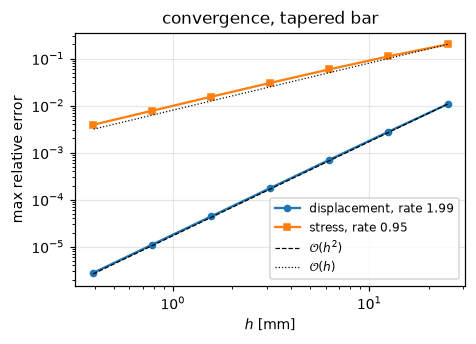

observed convergence rates: displacement 1.99, stress 0.95
relative stress error at the element midpoints: [1.39e-16 2.78e-16 8.33e-16 4.86e-15 5.41e-15 5.00e-14 4.47e-14]


In [21]:
alpha = 0.5
A_taper = lambda x: AREA * (1.0 - alpha * x / LEN)
u_taper = lambda x: FORCE * LEN / (E_MOD * AREA * alpha) * np.log(1.0 / (1.0 - alpha * x / LEN))
sig_taper = lambda x: FORCE / A_taper(x)

resD = fe_analysis(LEN, 12, E_MOD, A_taper, forces={12: FORCE}, n_quad=3)
plot_result(resD, "tapered bar, 12 elements", exact_u=u_taper, exact_sig=sig_taper)

n_els = np.array([2, 4, 8, 16, 32, 64, 128])
xs_fine = np.linspace(0.0, LEN, 4001)
err_u, err_s, err_mid = [], [], []
for n in n_els:
    r = fe_analysis(LEN, n, E_MOD, A_taper, forces={n: FORCE}, n_quad=3)
    xm = 0.5 * (r["x"][:-1] + r["x"][1:])
    # the piecewise constant FE stress, evaluated on a fine grid
    owner = np.clip(np.searchsorted(r["x"], xs_fine, side="right") - 1, 0, n - 1)
    err_u.append(np.max(np.abs(r["d"] - u_taper(r["x"]))) / u_taper(LEN))
    err_s.append(np.max(np.abs(r["stress"][owner] - sig_taper(xs_fine))) / sig_taper(LEN))
    err_mid.append(np.max(np.abs(r["stress"] - sig_taper(xm))) / sig_taper(LEN))
err_u, err_s, err_mid = np.array(err_u), np.array(err_s), np.array(err_mid)

h = LEN / n_els
pu = np.polyfit(np.log(h), np.log(err_u), 1)[0]
ps = np.polyfit(np.log(h), np.log(err_s), 1)[0]

fig, ax = plt.subplots(figsize=(4.4, 3.2))
ax.loglog(h, err_u, "o-", ms=4, label=f"displacement, rate {pu:.2f}")
ax.loglog(h, err_s, "s-", ms=4, label=f"stress, rate {ps:.2f}")
ax.loglog(h, err_u[0] * (h / h[0]) ** 2, "k--", lw=0.8, label=r"$\mathcal{O}(h^2)$")
ax.loglog(h, err_s[0] * (h / h[0]) ** 1, "k:", lw=0.8, label=r"$\mathcal{O}(h)$")
ax.set(xlabel="$h$ [mm]", ylabel="max relative error", title="convergence, tapered bar")
ax.legend(fontsize=8)
plt.show()

print(f"observed convergence rates: displacement {pu:.2f}, stress {ps:.2f}")
print("relative stress error at the element midpoints:", np.array2string(err_mid, precision=2))
assert 1.8 < pu < 2.3, pu
assert 0.8 < ps < 1.3, ps
assert np.max(err_mid) < 1e-12, "the midpoint stress should be superconvergent here"

The measured rates are $\mathcal{O}(h^2)$ for the displacement and $\mathcal{O}(h)$ for the stress,
exactly as predicted in Part I: the stress involves a derivative of the interpolant and therefore
loses one order.

The last line of output shows a bonus: at the **element midpoints** the stress is exact to machine
precision, not merely $\mathcal{O}(h)$. The reason is specific to this problem. Simpson's rule
integrates the linear $A(x)$ exactly, so $K^e = E\bar A_e/h\,[[1,-1],[-1,1]]$ with $\bar A_e$ the
mean area of the element; with no body force the internal normal force is $F$ in every element,
hence $\sigma^e_{\mathrm{FE}} = F/\bar A_e$, and for a linear $A$ the mean area is exactly $A$ at the
midpoint. This is the simplest instance of the *superconvergent* stress points that production codes
exploit (Gauss points in general), and it is the reason the $\mathcal{O}(h)$ rate above has to be
measured against the exact stress over the whole element rather than at its midpoint.

### Case E — body force: the bar hanging under its own weight

A final check with the body-force term switched on. For a vertical bar clamped at the top,
$b = g$ and $u(x) = \rho g (2lx - x^2)/(2E)$, which is quadratic and therefore *not* in the finite
element space; the nodal values are nevertheless exact (a 1D superconvergence property), while the
stress carries an $\mathcal{O}(h)$ error.

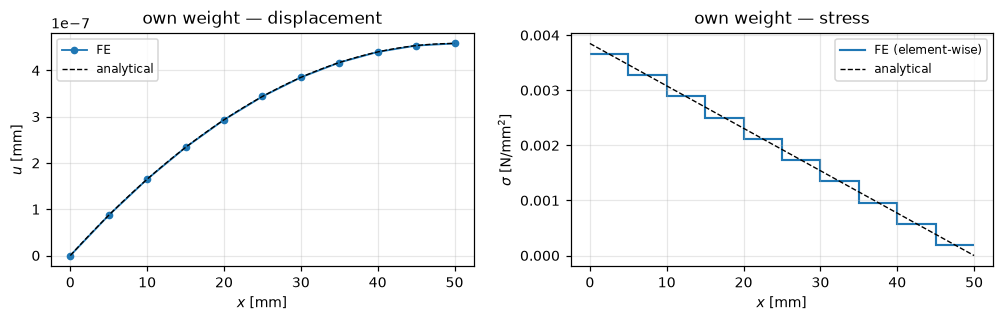

tip displacement: 4.583839e-07 mm   analytical 4.583839e-07 mm
max nodal error : 1.429e-21 mm
reaction        : -9.626062e-02 N   weight = -9.626063e-02 N


In [22]:
rho_steel = 7.85e-9      # t/mm^3
g = 9810.0               # mm/s^2
n = 10
resE = fe_analysis(LEN, n, E_MOD, AREA, rho=rho_steel, b=g, n_quad=2)
u_grav = lambda x: rho_steel * g * (2 * LEN * x - x ** 2) / (2 * E_MOD)
sig_grav = lambda x: rho_steel * g * (LEN - x)

plot_result(resE, "own weight", exact_u=u_grav, exact_sig=sig_grav)
print("tip displacement:", f"{resE['d'][-1]:.6e} mm   analytical {u_grav(LEN):.6e} mm")
print("max nodal error :", f"{np.max(np.abs(resE['d'] - u_grav(resE['x']))):.3e} mm")
print("reaction        :", f"{resE['reactions'][0]:.6e} N   weight = {-rho_steel * g * AREA * LEN:.6e} N")

assert np.allclose(resE["d"], u_grav(resE["x"]), atol=1e-14)
assert np.isclose(resE["reactions"][0], -rho_steel * g * AREA * LEN, rtol=1e-12)

## Summary

| Case | Setup | Result | Error |
|------|-------|--------|-------|
| 5 | 1 element, $u_1 = 0$, $F$ at node 2 | $\hat u_2 = 4.7619\cdot10^{-5}$ mm, $\sigma = 0.2$ N/mm² | $< 10^{-15}$ |
| 8 A | 6 elements, clamped–loaded | affine $u$, $\sigma = 0.2$ N/mm² on every element | $< 10^{-15}$ |
| 8 B | 6 elements, two forces | piecewise constant $\sigma$ with a jump at the loaded node | exact |
| 8 C | 6 elements, $u_1 = 0$, $u_7 = \bar u$ | uniform stretch, reactions $\mp EA\bar u/l$ | exact |
| 8 D | tapered bar $A(x)$ | $\mathcal{O}(h^2)$ in $u$, $\mathcal{O}(h)$ in $\sigma$ | measured |
| 8 E | own weight | nodal displacements exact, $\sigma$ with $\mathcal{O}(h)$ error | $< 10^{-14}$ |

Every hand calculation of Part I — the element matrix $\frac{EA}{h}[[1,-1],[-1,1]]$, the assembled
spring system, its singularity and null space, the permutation matrix, the reduced $1\times1$ system
and its solution $Fl/(EA)$ — has been reproduced by the code and asserted numerically. The code
consists of seven short, independent routines (`shape_functions`, `shape_derivatives`, `quadrature`,
`element_stiffness`, `element_load`, `assemble`, `apply_dirichlet`) plus the driver `fe_analysis`;
nothing in them is specific to the bar problem except the one-dimensional connectivity, which is the
point of the exercise.